In [1]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [2]:
df = pd.read_csv('/content/play_tennis.csv')

FileNotFoundError: [Errno 2] No such file or directory: '/content/play_tennis.csv'

In [ ]:
df

,day,outlook,temp,humidity,wind,play
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes
5,D6,Rain,Cool,Normal,Strong,No
6,D7,Overcast,Cool,Normal,Strong,Yes
7,D8,Sunny,Mild,High,Weak,No
8,D9,Sunny,Cool,Normal,Weak,Yes
9,D10,Rain,Mild,Normal,Weak,Yes


In [ ]:
le = {}
df_enc = df.copy()
for col in df.columns:
  le[col] = LabelEncoder()
  df_enc[col] = le[col].fit_transform(df[col])

In [ ]:
df_enc

,day,outlook,temp,humidity,wind,play
0,0,2,1,0,1,0
1,6,2,1,0,0,0
2,7,0,1,0,1,1
3,8,1,2,0,1,1
4,9,1,0,1,1,1
5,10,1,0,1,0,0
6,11,0,0,1,0,1
7,12,2,2,0,1,0
8,13,2,0,1,1,1
9,1,1,2,1,1,1


In [ ]:
x = df_enc[['day','outlook','temp','humidity','wind']]
y = df_enc['play']

In [ ]:
x

,day,outlook,temp,humidity,wind
0,0,2,1,0,1
1,6,2,1,0,0
2,7,0,1,0,1
3,8,1,2,0,1
4,9,1,0,1,1
5,10,1,0,1,0
6,11,0,0,1,0
7,12,2,2,0,1
8,13,2,0,1,1
9,1,1,2,1,1


In [ ]:
y

,play
0,0
1,0
2,1
3,1
4,1
5,0
6,1
7,0
8,1
9,1


In [3]:
model = CategoricalNB()
model.fit(x, y)

NameError: name 'x' is not defined

In [ ]:
test = [0,2,1,0,1]

In [ ]:
test

[0, 2, 1, 0, 1]

In [ ]:
test_samples = [[0, 2, 1, 0, 1]]
print("\n---prediction-----------------------------------")
for t in test_samples:
    row_df = pd.DataFrame([[t[0], t[1], t[2], t[3], t[4]]], columns=x.columns)

    pred = le['play'].inverse_transform(model.predict(row_df))[0]
    prob = model.predict_proba(row_df)[0]

    orig_day = le['day'].inverse_transform([t[0]])[0]
    orig_outlook = le['outlook'].inverse_transform([t[1]])[0]
    orig_temp = le['temp'].inverse_transform([t[2]])[0]
    orig_humidity = le['humidity'].inverse_transform([t[3]])[0]
    orig_wind = le['wind'].inverse_transform([t[4]])[0]

    print(f"input : day = {orig_day}, outlook = {orig_outlook}, temp = {orig_temp}, humidity = {orig_humidity}, wind = {orig_wind}")
    print(f"output : play = {pred}")
    print(f"p(No) = {prob[0]:.4f}")
    print(f"p(Yes) = {prob[1]:.4f}")


---prediction-----------------------------------
input : day = D1, outlook = Sunny, temp = Hot, humidity = High, wind = Weak
output : play = No
p(No) = 0.8422
p(Yes) = 0.1578


In [ ]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y,y_pred)*100:.2f}%")


Training Accuracy: 92.86%


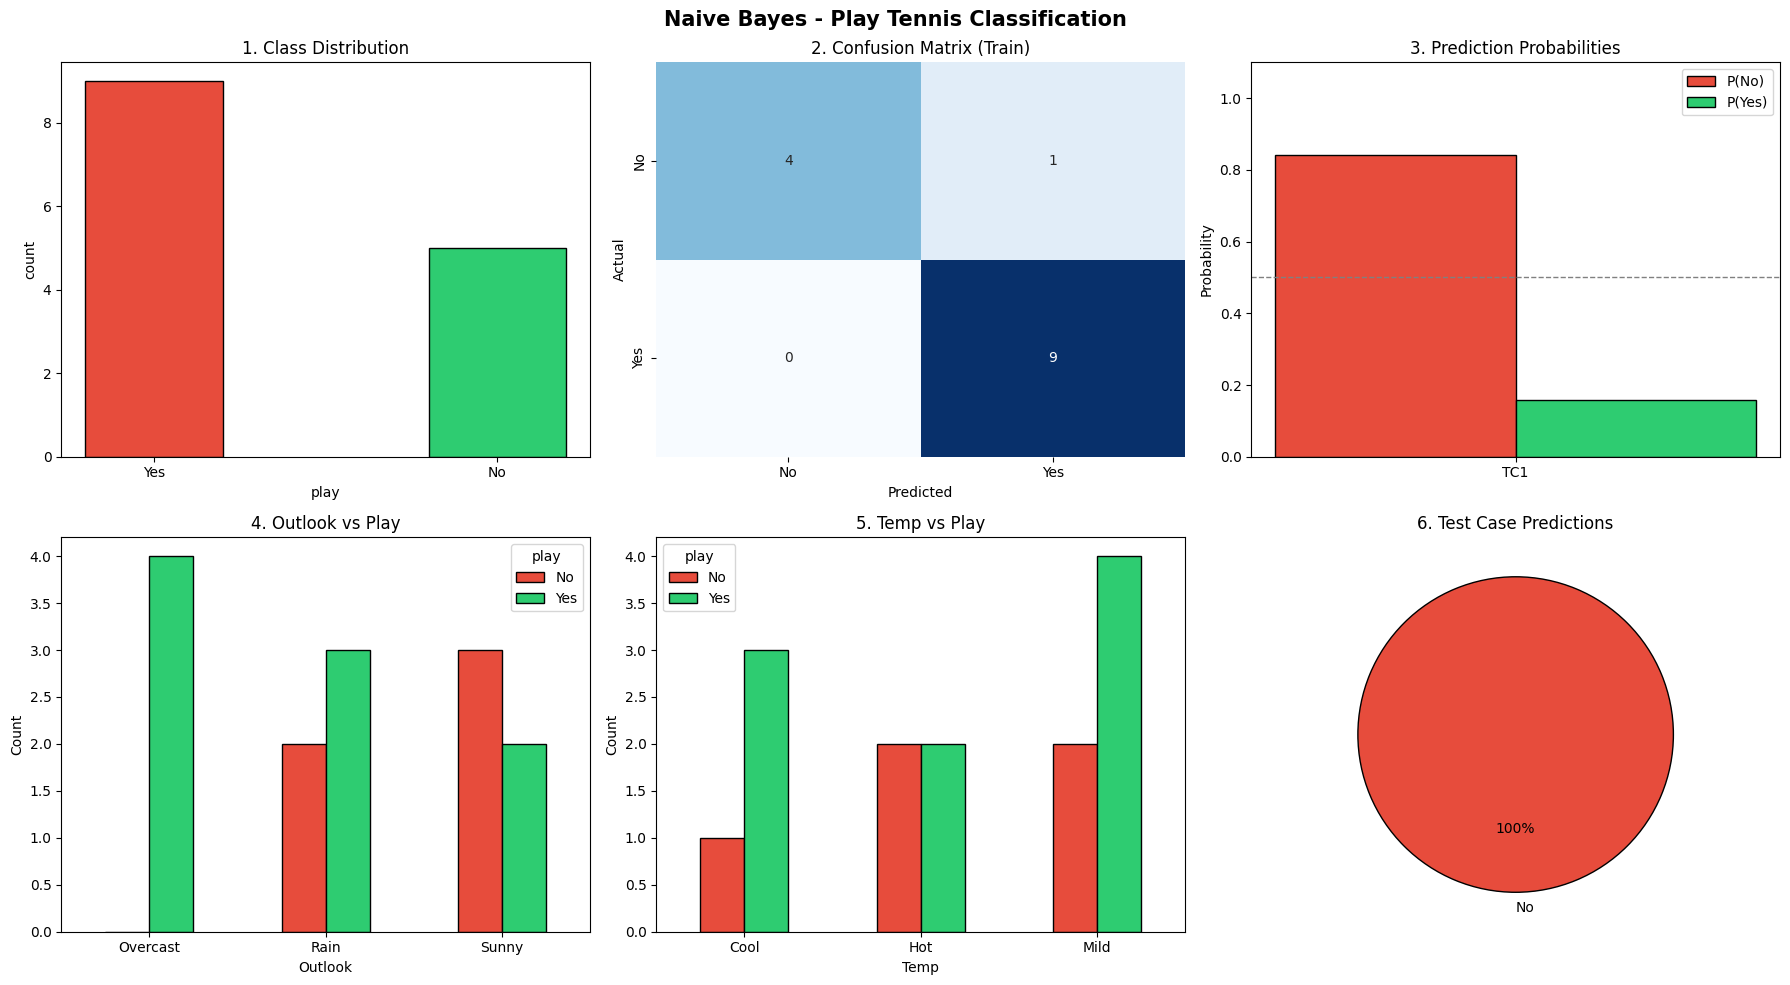

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Calculate predictions for test cases correctly (using a 2D array representation)
test_df = pd.DataFrame([test], columns=x.columns)
test_predictions = model.predict(test_df)

# Updated subplot grid to 2 rows and 3 columns to host all 6 plots correctly
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Naive Bayes - Play Tennis Classification", fontsize=15, fontweight='bold')

# 1. Class Distribution
counts = df['play'].value_counts()
axes[0, 0].bar(counts.index.astype(str), counts.values, color=['#e74c3c', '#2ecc71'], edgecolor='black', width=0.4)
axes[0, 0].set_title("1. Class Distribution")
axes[0, 0].set_xlabel("play")
axes[0, 0].set_ylabel("count")

# 2. Confusion Matrix of Training Data
cm = confusion_matrix(y, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 1], cbar=False,
            xticklabels=le['play'].classes_, yticklabels=le['play'].classes_)
axes[0, 1].set_title("2. Confusion Matrix (Train)")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# 3. Prediction Probabilities (Grouped Bar)
test_cases = [test]
probs_no = [prob[0]]
probs_yes = [prob[1]]

tc_labels = [f"TC{i+1}" for i in range(len(test_cases))]
x_indices = np.arange(len(tc_labels))
w = 0.3

axes[0, 2].bar(x_indices - w/2, probs_no, w, label='P(No)',
              color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_indices + w/2, probs_yes, w, label='P(Yes)',
              color='#2ecc71', edgecolor='black')
axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_xticks(x_indices)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

# 4. Outlook vs Play
outlook_counts = df.groupby(['outlook', 'play']).size().unstack(fill_value=0)
outlook_counts.plot(
    kind='bar',
    ax=axes[1, 0],
    color=['#e74c3c', '#2ecc71'],
    edgecolor='black',
    rot=0
)
axes[1, 0].set_title("4. Outlook vs Play")
axes[1, 0].set_xlabel("Outlook")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(title="play")

# 5. Temp vs Play
temp_counts = df.groupby(['temp', 'play']).size().unstack(fill_value=0)
temp_counts.plot(
    kind='bar',
    ax=axes[1, 1],
    color=['#e74c3c', '#2ecc71'],
    edgecolor='black',
    rot=0
)
axes[1, 1].set_title("5. Temp vs Play")
axes[1, 1].set_xlabel("Temp")
axes[1, 1].set_ylabel("Count")
axes[1, 1].legend(title="play")

# 6. Pie Chart - Final Predictions (Using correct 'play' label decoder)
decoded_predictions = le['play'].inverse_transform(test_predictions)
pred_counts = pd.Series(decoded_predictions).value_counts()
colors_pie = ['#e74c3c' if str(i) == 'No' else '#2ecc71' for i in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, autopct='%1.0f%%',
              colors=colors_pie, startangle=90,
              wedgeprops={'edgecolor': 'black'})
axes[1, 2].set_title('6. Test Case Predictions')

plt.tight_layout()
plt.show()